# 05 · Phase 2: a global DeepAR model

Phase 1 found where the local Kalman filter falls short: **sparse and new items**, where it cannot borrow patterns from other series. Phase 2 tests a global *deep* probabilistic model on exactly the same backtest.

**Model** (`prism/models/deepar.py`, Salinas et al., 2020), written from scratch in PyTorch:

* one autoregressive **LSTM** (2 layers, 64 units) trained on windows drawn from all 1,500 series;
* inputs at each day: sales 1, 7, 14 and 28 days earlier, divided by a per-window scale $v = 1 + \text{mean}$ of the context; calendar (weekday, month, week, events, days to/since an event), SNAP, relative price, item age; and learned **embeddings** of item, department, category and store;
* output: a **negative binomial** distribution for the day's demand, $\mu = v\,\text{softplus}(\cdot)$, $\alpha = \text{softplus}(\cdot)/\sqrt v$, a count likelihood that handles zeros without a log transform;
* forecasts: **200 ancestral sample paths** per series (each path feeds its own draws back in), whose mean is the point forecast and whose empirical quantiles are the 7 predictive quantiles.

**Same rules as Phase 1.**

* Stockouts are **marked, never imputed**: flagged and pre-launch days get zero weight in the likelihood, and enter the inputs as 0 together with an "observed" flag.
* No leakage: the model only receives the panel truncated at the origin, and future sales are sampled, never read.
* Epochs are chosen by early stopping on the **last 28 days inside the training window**, then the model is retrained from scratch on the full window, as LightGBM is with its boosting rounds.
* Refit from scratch at each of the 5 origins and scored on the identical 209,860 cells.

**Ablation.** `deepar_noid` is the same network without any ID embeddings: it isolates how much DeepAR gains from knowing *which* item it forecasts.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display
from prism.backtest import load_diagnostics
from prism.config import load_config, resolve
from prism.metrics import summarize
from prism import plots
plots.apply_style()
cfg = load_config()
ev = pd.read_parquet(resolve("results/evaluation.parquet"))
masked = ev[~ev["stockout"]]
FIG, CACHE = resolve("report/figures"), resolve("results/cache")
order = {m: i for i, m in enumerate(plots.MODEL_ORDER)}
cols = ["model", "MAE", "RMSE", "WAPE", "RMSSE", "Pinball", "SPL", "Cov80", "Cov90", "Width90"]
show = lambda t: t.sort_values("model", key=lambda s: s.map(order))[cols].round(3).set_index("model")
print(f"scored cells per model: {len(ev) // ev['model'].nunique():,}")

scored cells per model: 209,860


## 1. Training: early stopping inside the training window

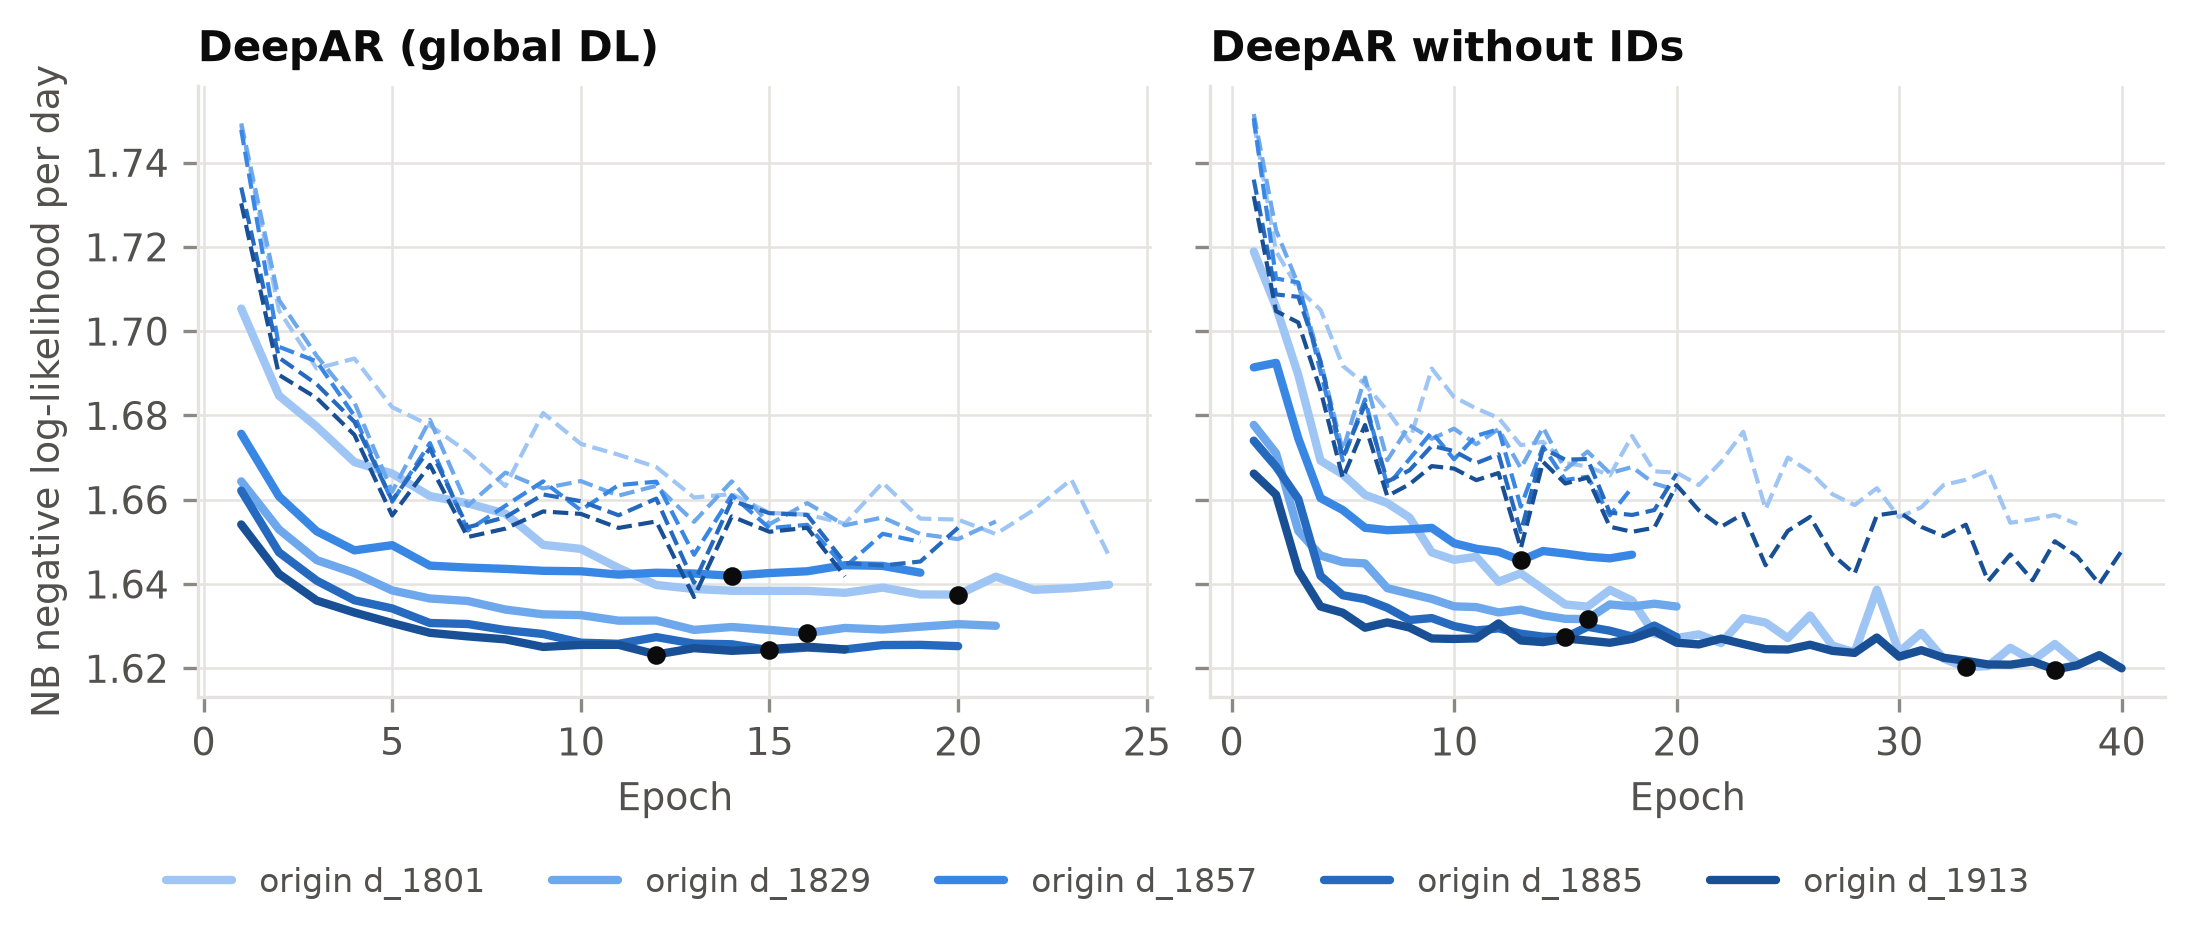

best_epochs             train_seconds            
model       deepar deepar_noid        deepar deepar_noid
origin                                                  
1801            19          33         164.0       307.0
1829            16          15         145.0       124.0
1857            14          13         137.0       184.0
1885            15          15         146.0       230.0
1913            12          37         132.0       320.0

In [2]:
display(Image(FIG / "deepar_training.png", width=900))
curves = pd.read_csv(resolve("results/deepar_training.csv"))
curves.groupby(["model", "origin"])[["best_epochs", "train_seconds"]].first().round(0).unstack("model")

Early stopping picks **about 15 epochs** for DeepAR (23 without IDs) out of a 40-epoch budget, about 2.5 minutes per origin on an Apple M3 GPU (MPS). Dashed lines are training NLL, solid lines validation NLL on the 28 days just before the origin: validation loss bottoms out and then rises, so the stopping rule matters. Without IDs the network has less capacity to memorise, so it trains longer before overfitting.

## 2. Headline table (stockout-masked)

In [3]:
show(summarize(masked))

,MAE,RMSE,WAPE,RMSSE,Pinball,SPL,Cov80,Cov90,Width90
model,,,,,,,,,
seasonal_naive,2.101,4.000,0.757,0.978,0.610,0.358,0.857,0.924,7.087
tsb,1.664,3.181,0.600,0.753,0.494,0.281,0.790,0.887,6.549
kalman,1.615,3.479,0.582,0.744,0.485,0.280,0.818,0.903,7.563
lightgbm,1.579,3.040,0.569,0.732,0.466,0.264,0.798,0.915,6.523
lightgbm_lag28,1.589,3.061,0.573,0.733,0.469,0.265,0.796,0.915,6.542
deepar,1.567,3.070,0.565,0.736,0.464,0.263,0.900,0.948,6.265
deepar_noid,1.564,3.048,0.564,0.734,0.463,0.264,0.901,0.949,6.147


* **DeepAR has the best probabilistic score**: SPL 0.2635 vs 0.2643 for LightGBM and 0.2801 for the Kalman filter, and the best WAPE (0.565 vs 0.569 and 0.582). Against the filter that is a **6.0 % lower SPL**, the same size of gain as LightGBM's.
* Against LightGBM the difference is **tiny**: the Diebold–Mariano test on daily pinball loss is not significant (p = 0.28). On absolute error DeepAR is slightly but significantly better (p = 0.025, better on 66 % of series). LightGBM keeps a slightly lower RMSE (3.04 vs 3.07): its Tweedie mean model is a little better at the spikes.
* **The ID embeddings add nothing**: DeepAR and DeepAR-without-IDs are indistinguishable (SPL 0.2635 vs 0.2635, p = 0.30). The global gain comes from learning shared *dynamics* (scaled lags, calendar, price) across all series, not from knowing which item it is.
* **Quantiles never cross**: they are empirical quantiles of one set of sample paths, while LightGBM's 7 separate quantile models cross in 55 % of cells (mostly by tiny amounts).

In [4]:
tests = pd.read_csv(resolve("results/significance_tests.csv"))
tests[tests["model_a"] == "deepar"].round(4)

,model_a,model_b,loss,days,mean_diff,DM,p_value,share_series_a_better,wilcoxon_p
10,deepar,kalman,pinball,140,-0.0214,-7.6212,0.0000,0.7911,0.0000
11,deepar,kalman,abs_err,140,-0.0478,-5.2364,0.0000,0.7410,0.0000
12,deepar,lightgbm,pinball,140,-0.0019,-1.0904,0.2774,0.5828,0.0000
13,deepar,lightgbm,abs_err,140,-0.0117,-2.2664,0.0250,0.6622,0.0000
14,deepar,deepar_noid,pinball,140,0.0012,1.0464,0.2972,0.5220,0.6208
15,deepar,deepar_noid,abs_err,140,0.0032,0.9927,0.3226,0.3865,0.6374


## 3. Where does the deep model help? Demand class and cold start

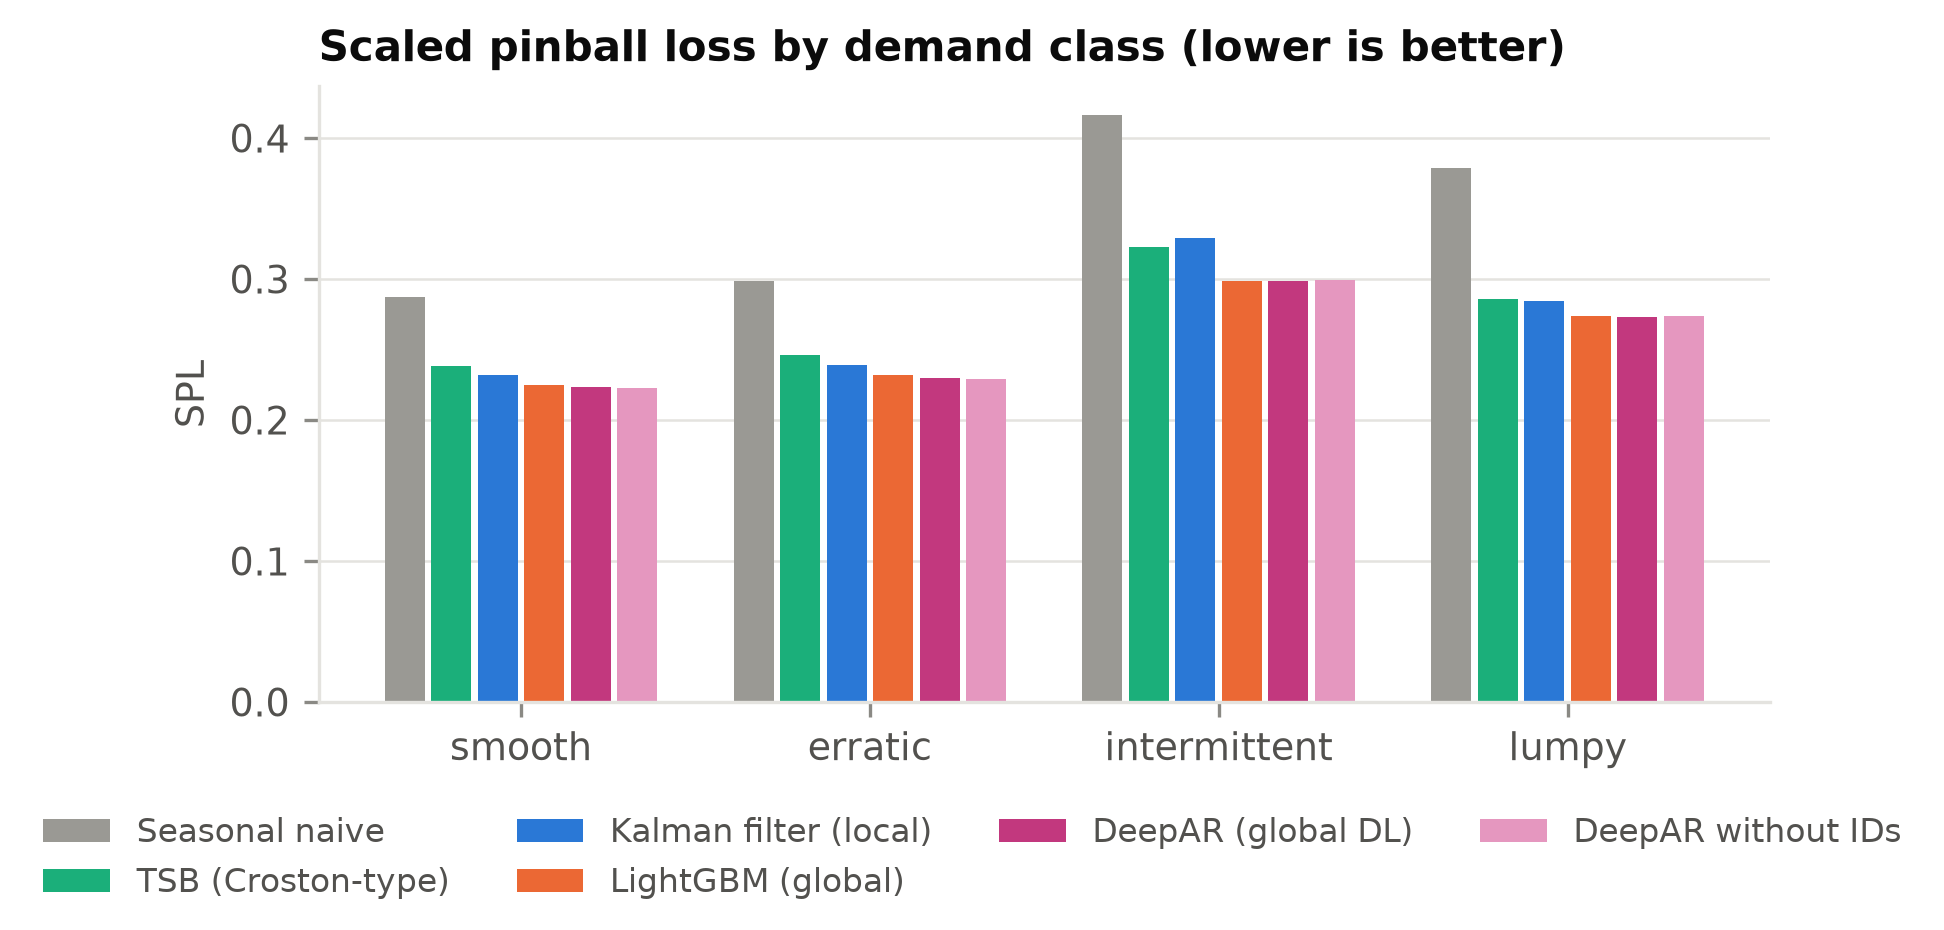

demand_class,erratic,intermittent,lumpy,smooth
model,,,,
deepar,0.230,0.298,0.273,0.223
deepar_noid,0.229,0.299,0.274,0.223
kalman,0.239,0.329,0.285,0.232
lightgbm,0.232,0.299,0.274,0.225
lightgbm_lag28,0.233,0.299,0.274,0.226
seasonal_naive,0.299,0.416,0.379,0.287
tsb,0.246,0.322,0.286,0.239


In [5]:
display(Image(FIG / "spl_by_class.png", width=650))
summarize(masked, ["demand_class"]).query("demand_class != 'new'").pivot(index="model", columns="demand_class", values="SPL").round(3)

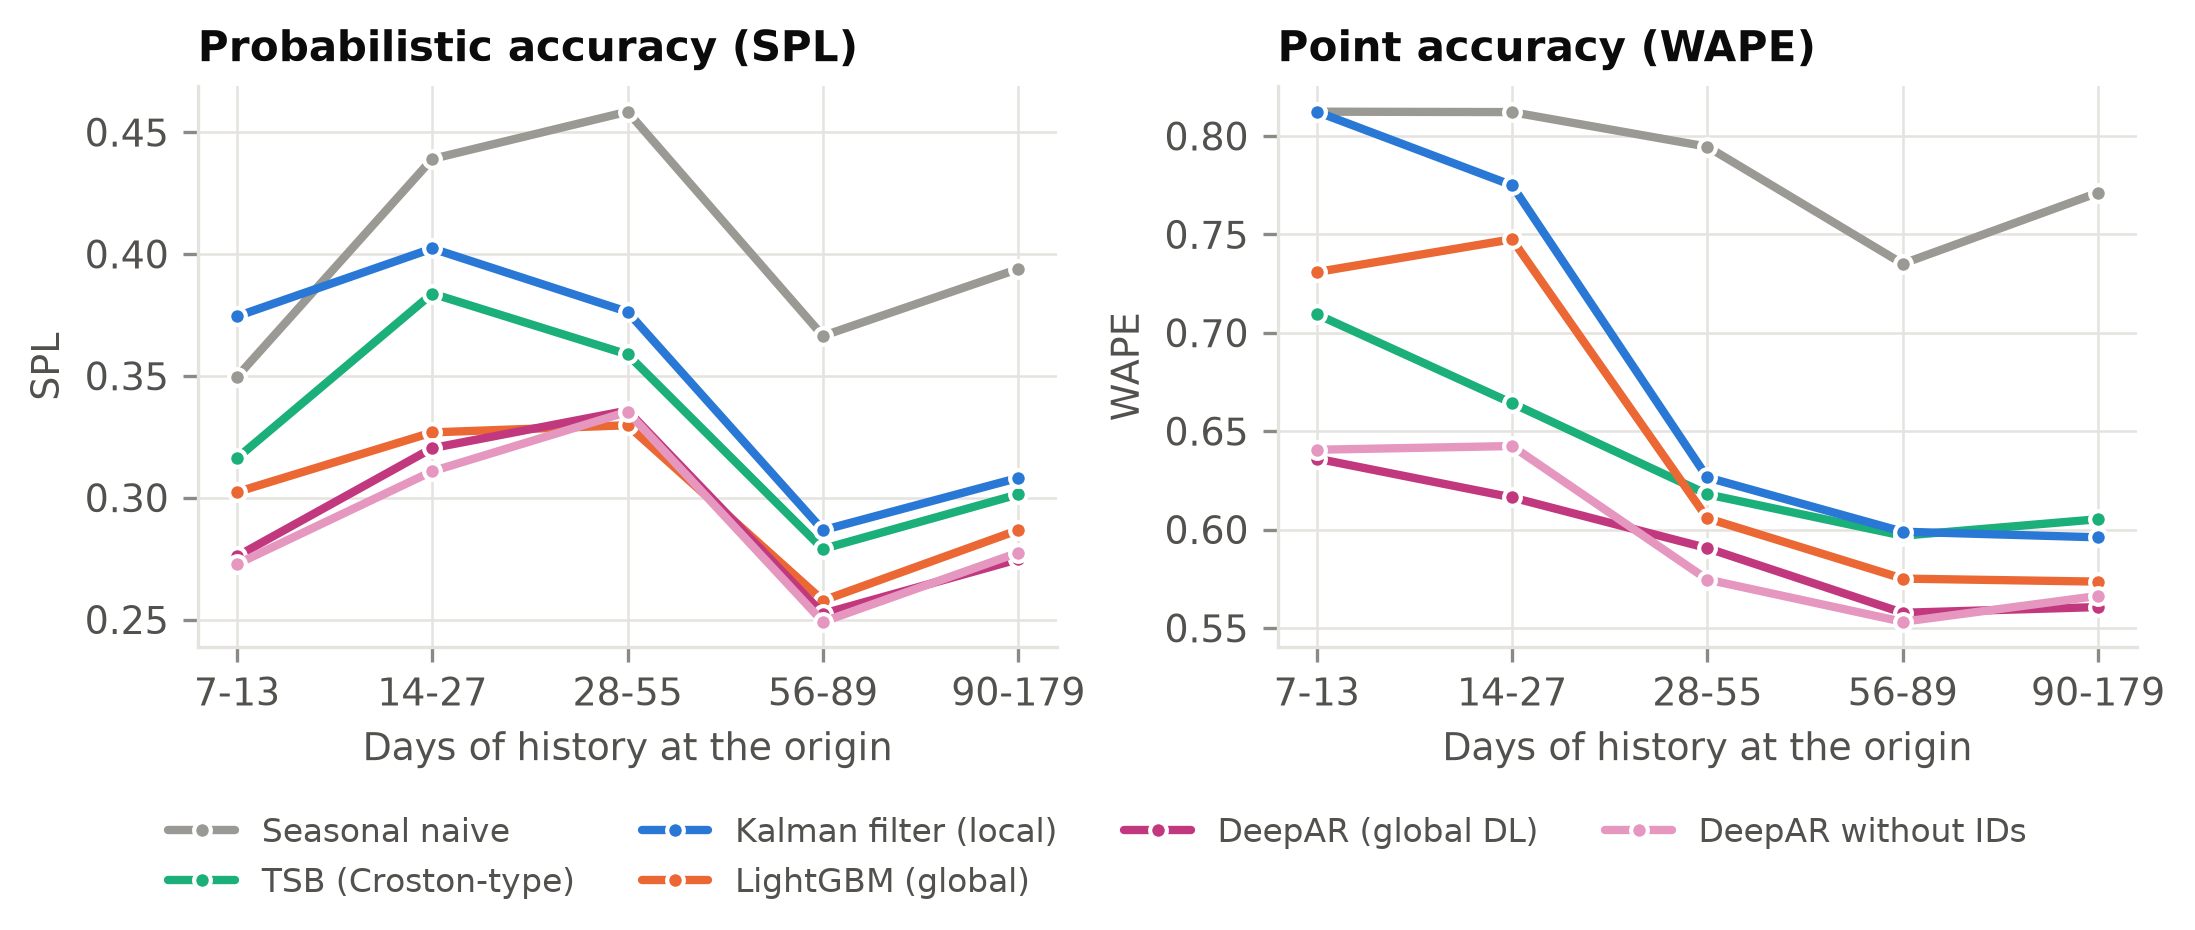

SPL                              Cov90                       \
history          7-13  14-27  28-55  56-89 90-179   7-13  14-27  28-55  56-89   
model                                                                           
deepar          0.276  0.320  0.336  0.252  0.275  0.922  0.883  0.928  0.948   
deepar_noid     0.273  0.311  0.335  0.249  0.277  0.928  0.910  0.928  0.947   
kalman          0.374  0.402  0.376  0.287  0.308  0.709  0.754  0.853  0.889   
lightgbm        0.302  0.327  0.330  0.258  0.287  0.897  0.863  0.880  0.878   
seasonal_naive  0.350  0.439  0.458  0.366  0.394  0.921  0.924  0.853  0.884   
tsb             0.316  0.384  0.359  0.279  0.301  0.894  0.891  0.826  0.860   

                       
history        90-179  
model                  
deepar          0.946  
deepar_noid     0.943  
kalman          0.893  
lightgbm        0.881  
seasonal_naive  0.909  
tsb             0.875

In [6]:
display(Image(FIG / "cold_start_curve.png", width=900))
cs = pd.read_csv(resolve("results/cold_start_learning_curve.csv"))
hist = ["7-13", "14-27", "28-55", "56-89", "90-179"]
pd.concat({m: cs.pivot(index="model", columns="history", values=m)[hist] for m in ["SPL", "Cov90"]}, axis=1).round(3)

* By demand class DeepAR and LightGBM are within 0.003 SPL of each other everywhere; both beat the filter most on **intermittent** series (0.298 vs 0.329, ≈ 9 %).
* On **cold start** DeepAR is the best model: SPL 0.282 vs 0.286 (LightGBM) and 0.328 (Kalman) on cells with under 90 days of history. With **7–13 days** of history its SPL is 0.276 vs 0.302 and 0.374, and its 90 % interval covers 92 % of outcomes, against 90 % for LightGBM and only 71 % for the filter.
* DeepAR has never seen a cold-start series as a special case: windows are drawn from all series, and a window that starts before launch simply has unobserved context. Training on such windows teaches the network what to forecast from a few days of history.

## 4. Calibration and intervals

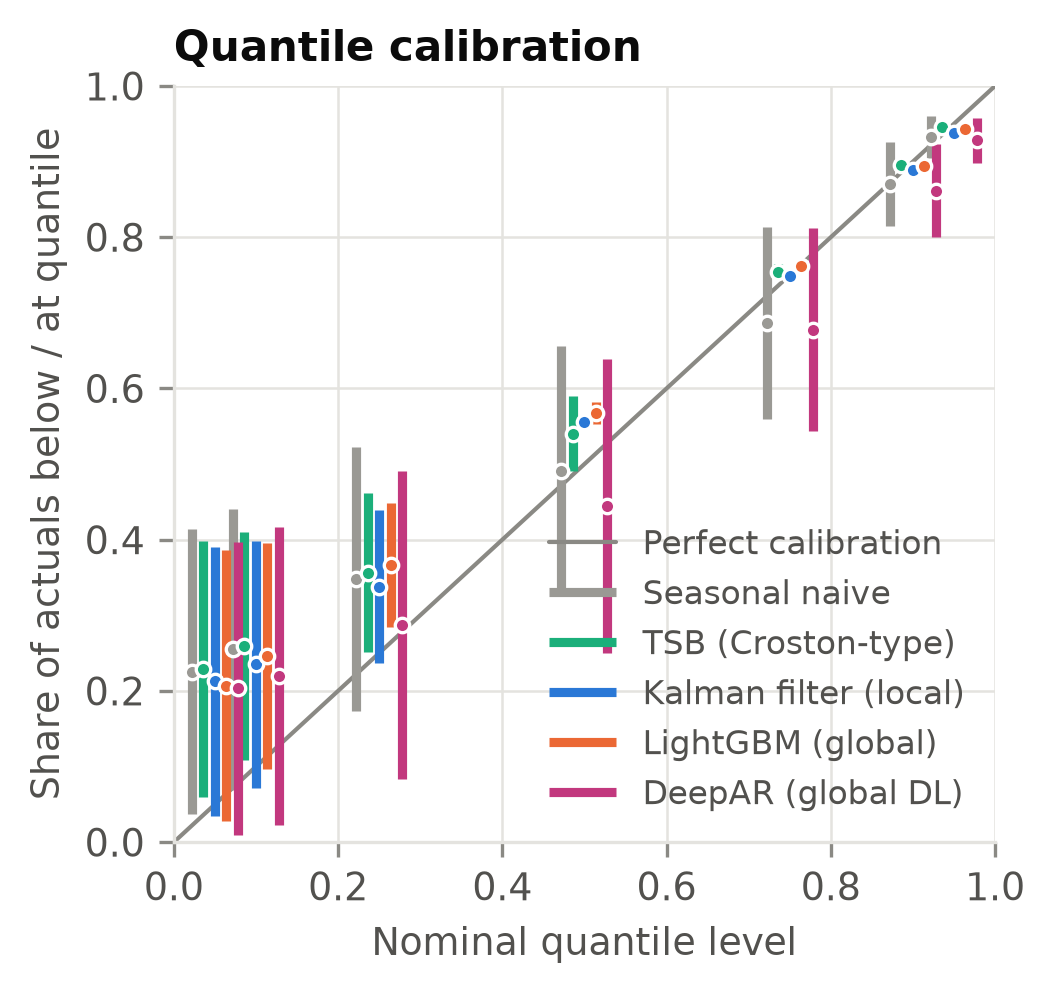

model,deepar,kalman,lightgbm
level,,,
0.05,0.397,0.391,0.386
0.10,0.416,0.399,0.395
0.25,0.490,0.439,0.448
0.50,0.638,0.560,0.582
0.75,0.813,0.749,0.762
0.90,0.923,0.889,0.895
0.95,0.957,0.938,0.943


In [7]:
display(Image(FIG / "calibration.png", width=420))
cal = pd.read_csv(resolve("results/quantile_calibration.csv"))
cal[cal["model"].isin(["kalman", "lightgbm", "deepar"])].pivot(index="level", columns="model", values="at_or_below").round(3)

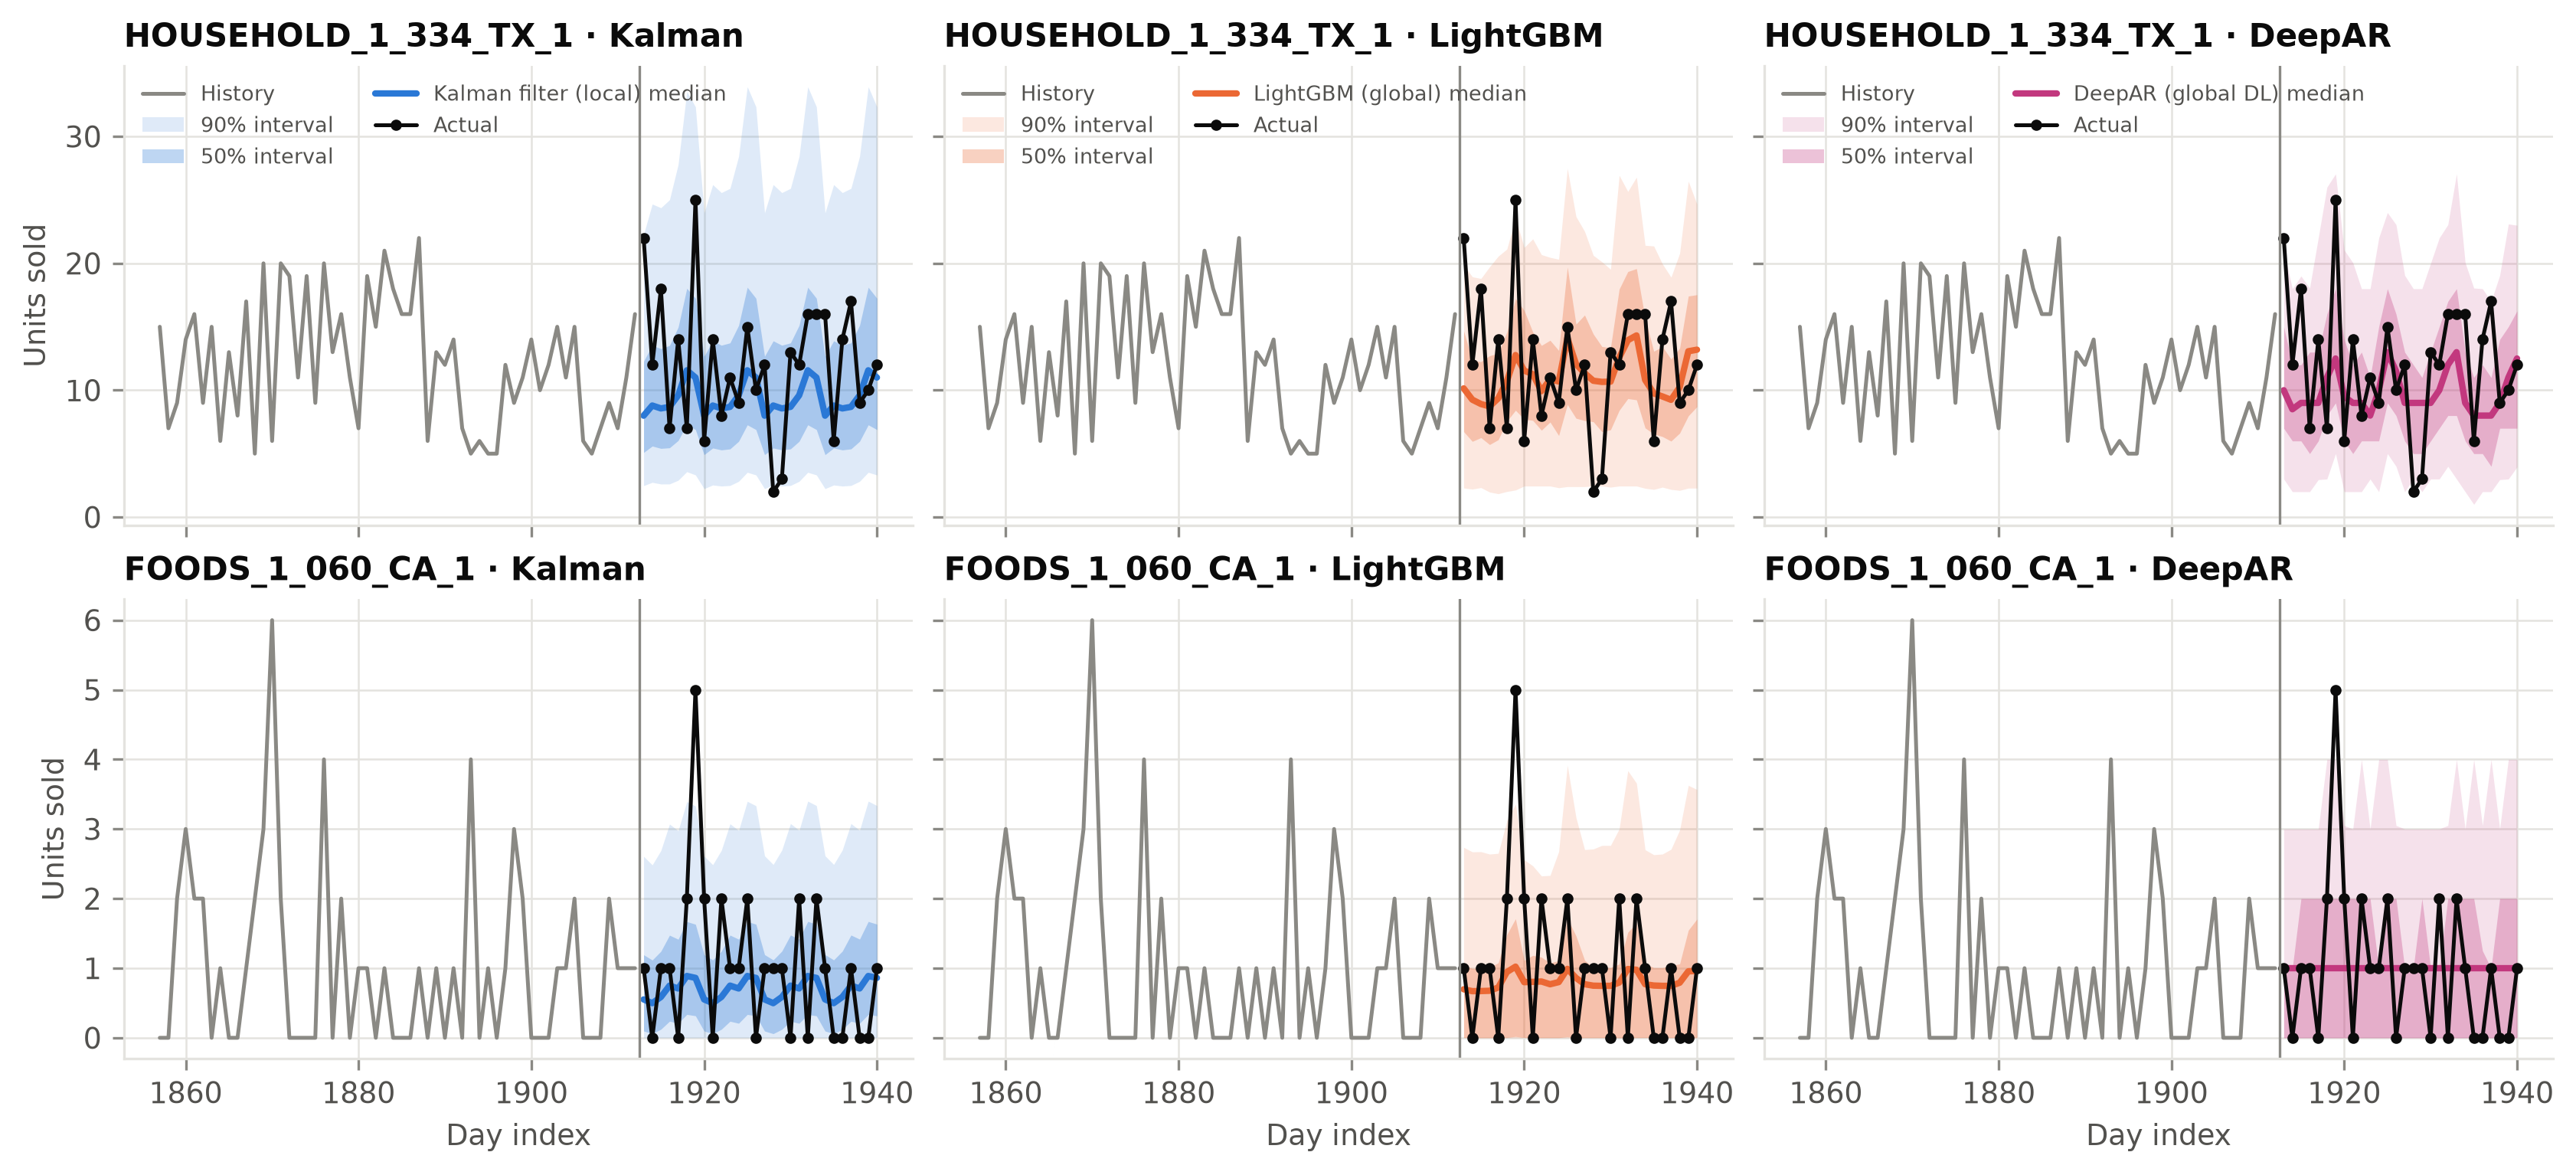

In [8]:
display(Image(FIG / "fan_charts.png", width=1000))

DeepAR's quantiles are **integers** (empirical quantiles of integer sample paths), so many outcomes fall exactly on an interval bound. That is why its 80 %/90 % coverage (0.900/0.948) is above nominal even though its 90 % intervals are the **narrowest** of all models (6.27 units vs 6.52 for LightGBM and 7.56 for the filter). Under the count-data criterion $P(y<q_\alpha) \le \alpha \le P(y\le q_\alpha)$, every DeepAR quantile is calibrated (e.g. 0.801 ≤ 0.9 ≤ 0.923). In the fan charts DeepAR's lower quantiles sit exactly at zero for the intermittent item, a point mass that comes from the negative binomial likelihood.

## 5. What the item embeddings learned

Each item gets a 16-dimensional embedding. Nothing tells the network which category an item belongs to through this vector, so if items of the same category end up close together, the network has learned shared behaviour from sales alone. Below: the first two principal components of the embeddings at the last origin.

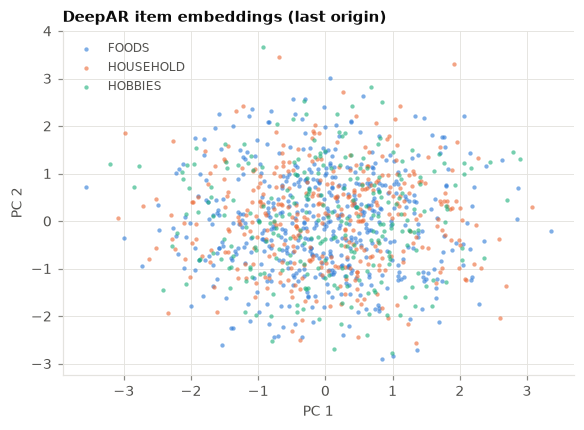

variance explained by PC1, PC2: [0.07709546 0.07354306]


In [9]:
emb = load_diagnostics(cfg, CACHE, "deepar", "item_embedding")
emb = emb[emb["origin"] == emb["origin"].max()]
E = emb[[c for c in emb.columns if c[0] == "e" and c[1:].isdigit()]].to_numpy()
E = E - E.mean(0)
U, S, Vt = np.linalg.svd(E, full_matrices=False)
pc = E @ Vt[:2].T
cat = emb["item_id"].str.split("_").str[0].to_numpy()
fig, ax = plt.subplots(figsize=(5.2, 3.8))
for c, colour in zip(["FOODS", "HOUSEHOLD", "HOBBIES"], [plots.MODEL_COLORS["kalman"], plots.MODEL_COLORS["lightgbm"], plots.MODEL_COLORS["tsb"]]):
    m = cat == c
    ax.scatter(pc[m, 0], pc[m, 1], s=8, alpha=0.6, color=colour, label=c, lw=0)
ax.set_xlabel("PC 1"); ax.set_ylabel("PC 2"); ax.set_title("DeepAR item embeddings (last origin)")
ax.legend()
plt.show()
print(f"variance explained by PC1, PC2: {S[:2]**2 / (S**2).sum()}")

In [10]:
# does the embedding separate categories better than chance? nearest-neighbour category agreement
from numpy.linalg import norm
X = E / norm(E, axis=1, keepdims=True)
sim = X @ X.T
np.fill_diagonal(sim, -np.inf)
nn = sim.argmax(1)
agree = (cat[nn] == cat).mean()
chance = sum((cat == c).mean() ** 2 for c in np.unique(cat))
print(f"nearest neighbour has the same category: {agree:.1%} (chance {chance:.1%})")

nearest neighbour has the same category: 37.8% (chance 35.6%)


The embeddings carry **almost no category structure**: an item's nearest neighbour is in the same category 37.8 % of the time against 35.6 % by chance, and the first two principal components explain only about 7 % of the variance each, so the vectors are close to unstructured. This matches the ablation: the network barely uses item identity, because the scaled sales history and the covariates already tell it what it needs. For new items this is reassuring, since the model does not depend on having seen the item before.

## 6. Inventory decisions

In [11]:
dec = pd.read_csv(resolve("results/decision_costs.csv"))
dec.pivot(index="model", columns="policy", values=["total_cost", "fill_rate"]).round(3)

total_cost            fill_rate         
policy              point   quantile     point quantile
model                                                  
deepar          1345416.0   926490.0     0.761    0.923
kalman          1274945.0  1007217.0     0.782    0.946
lightgbm        1343679.0   931248.0     0.762    0.937
seasonal_naive  2016601.0  1037120.0     0.612    0.925
tsb             1377543.0   963557.0     0.757    0.939

With  = 9$,  = 1$ (order the 0.9 quantile), DeepAR's quantiles give the **lowest newsvendor cost** (926k vs 931k for LightGBM and 1,007k for the filter) and the fewest unsold units (564k vs 636k), at a slightly lower fill rate (0.923 vs 0.937). Ordering the point forecast instead costs 45 % more. Over the cost-ratio sweep DeepAR is cheapest up to about 9:1, and LightGBM is marginally cheaper at extreme ratios (15:1 and above), where the far upper tail matters most.

## Takeaways\n\n1. **A global deep model closes the same gap LightGBM did.** DeepAR beats the local Kalman filter by 6 % SPL (DM p ≈ 4·10⁻¹², better on 79 % of series), with the largest gains on intermittent and new items.
2. **It matches, but does not clearly beat, the tabular global model.** DeepAR vs LightGBM is a statistical tie on pinball loss; DeepAR is best at cold start, LightGBM slightly better on RMSE. DeepAR needs no hand-built lag features and no separate quantile models, and its quantiles are coherent by construction.
3. **Sharing comes from dynamics, not identity.** Removing every ID embedding changes nothing measurable, which is good news for truly new items: the model does not rely on having seen the item before.
4. **Uncertainty pays off in decisions.** DeepAR's sample-based quantiles give the lowest inventory cost at τ* = 0.9 and leave the fewest units unsold.